# 01 · AI4I 2020 dataset exploration

Milestone 01 of MaintenAI. Goal: understand the structure, labels, class imbalance and quirks of the dataset **before** any modelling, and confirm the leakage rules.

Nothing in this notebook trains a model.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from ml.data import schema as S
from ml.data.ingestion import load_ai4i, file_md5
from ml.data.validation import assert_no_leakage

FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e6", "axes.axisbelow": True})
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
pd.set_option("display.width", 140)

## 1. Load and validate

In [2]:
df, report = load_ai4i(ROOT / "data/raw/ai4i2020.csv")
print("MD5:", file_md5(ROOT / "data/raw/ai4i2020.csv"))
print(f"rows={report.n_rows} columns={report.n_columns} missing={report.missing_values} "
      f"duplicate rows={report.duplicate_rows} duplicate UDI={report.duplicate_udi}")
print("out-of-range values:", report.out_of_range or "none")
for w in report.warnings: print("WARNING:", w)
df.head()

MD5: f0adaa9c5e25366c6df1cc2684479871
rows=10000 columns=14 missing=0 duplicate rows=0 duplicate UDI=0
out-of-range values: none


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
print("Product ID unique per row:", df[S.PRODUCT_ID].is_unique)
print("Product ID prefix always equals Type:", (df[S.PRODUCT_ID].str[0] == df[S.TYPE]).all())
df[list(S.NUMERIC_FEATURES)].describe().T.round(2)

Product ID unique per row: True
Product ID prefix always equals Type: True


,count,mean,std,min,25%,50%,75%,max
Air temperature [K],10000.0,300.00,2.00,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,310.01,1.48,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,1538.78,179.28,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,39.99,9.97,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,107.95,63.65,0.0,53.0,108.0,162.0,253.0


**Observation.** Every row has its own Product ID, so the data contain no repeated machines. Machine-grouped validation is therefore impossible; the closest substitute is a split by product `Type`.

## 2. Target and class imbalance

In [4]:
vc = df[S.MACHINE_FAILURE].value_counts().sort_index()
print(vc.to_dict(), f"failure rate = {df[S.MACHINE_FAILURE].mean():.2%}")
print("Majority-class accuracy baseline:", f"{1 - df[S.MACHINE_FAILURE].mean():.2%}")
rate = df.groupby(S.TYPE)[S.MACHINE_FAILURE].agg(["count", "sum", "mean"]).loc[list(S.TYPE_LEVELS)]
rate.columns = ["machines", "failures", "failure rate"]; rate

{0: 9661, 1: 339} failure rate = 3.39%
Majority-class accuracy baseline: 96.61%


,machines,failures,failure rate
Type,,,
L,6000,235,0.039167
M,2997,83,0.027694
H,1003,21,0.020937


## 3. Failure modes and label consistency

In [5]:
modes = list(S.FAILURE_MODES)
n_modes = df[modes].sum(axis=1)
summary = pd.DataFrame({
    "rows flagged": df[modes].sum(),
    "of which Machine failure = 1": df.loc[df[S.MACHINE_FAILURE] == 1, modes].sum(),
})
print(summary)
print("failures with no mode flag:", int(((df[S.MACHINE_FAILURE] == 1) & (n_modes == 0)).sum()))
print("rows with a mode flag but no failure:", int(((df[S.MACHINE_FAILURE] == 0) & (n_modes > 0)).sum()))
print("rows with more than one mode:", int((n_modes > 1).sum()))
co = df.loc[n_modes > 1, modes].T.dot(df.loc[n_modes > 1, modes]); co

     rows flagged  of which Machine failure = 1
TWF            46                            46
HDF           115                           115
PWF            95                            95
OSF            98                            98
RNF            19                             1
failures with no mode flag: 9
rows with a mode flag but no failure: 18
rows with more than one mode: 24


,TWF,HDF,PWF,OSF,RNF
TWF,4,0,1,3,1
HDF,0,9,3,6,0
PWF,1,3,15,12,0
OSF,3,6,12,20,0
RNF,1,0,0,0,1


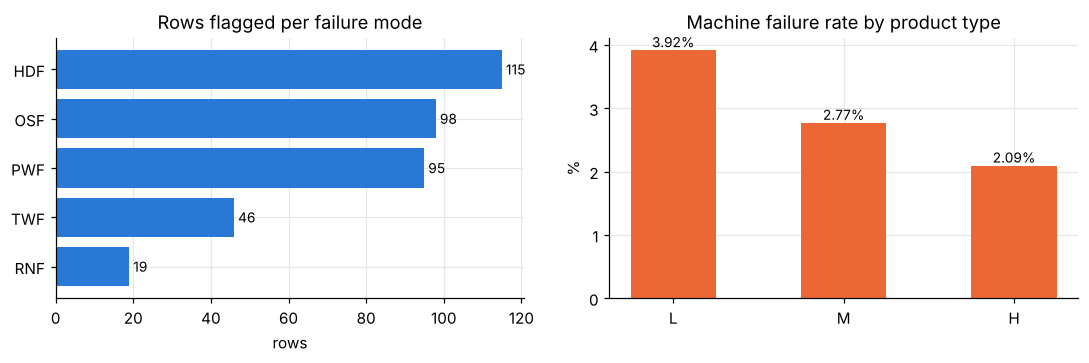

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
counts = df[modes].sum().sort_values()
ax[0].barh(counts.index, counts.values, color=BLUE)
for y, v in enumerate(counts.values): ax[0].text(v + 1, y, str(v), va="center", fontsize=9)
ax[0].set_title("Rows flagged per failure mode"); ax[0].set_xlabel("rows")
r = rate["failure rate"] * 100
ax[1].bar(r.index, r.values, color=ORANGE, width=0.5)
for x, v in enumerate(r.values): ax[1].text(x, v + 0.05, f"{v:.2f}%", ha="center", fontsize=9)
ax[1].set_title("Machine failure rate by product type"); ax[1].set_ylabel("%")
fig.tight_layout(); fig.savefig(FIG / "eda_failure_modes_and_types.png", dpi=150)

## 4. Operating variables by outcome

Machine failure                0        1
Air temperature [K]       299.97   300.89
Process temperature [K]   310.00   310.29
Rotational speed [rpm]   1540.26  1496.49
Torque [Nm]                39.63    50.17
Tool wear [min]           106.69   143.78


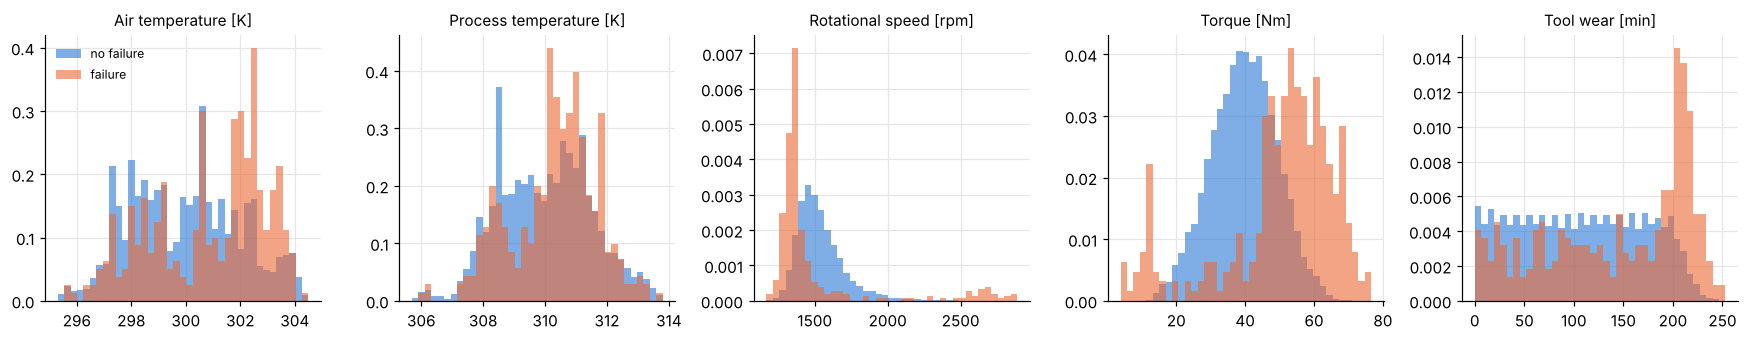

In [7]:
num = list(S.NUMERIC_FEATURES)
print(df.groupby(S.MACHINE_FAILURE)[num].mean().T.round(2))
fig, axes = plt.subplots(1, 5, figsize=(16, 3.2))
for ax, col in zip(axes, num):
    ok, bad = df.loc[df[S.MACHINE_FAILURE] == 0, col], df.loc[df[S.MACHINE_FAILURE] == 1, col]
    bins = np.linspace(df[col].min(), df[col].max(), 40)
    ax.hist(ok, bins=bins, density=True, alpha=0.6, color=BLUE, label="no failure")
    ax.hist(bad, bins=bins, density=True, alpha=0.6, color=ORANGE, label="failure")
    ax.set_title(col, fontsize=10)
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "eda_distributions_by_outcome.png", dpi=150)

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
Air temperature [K],1.000,0.876,0.023,-0.014,0.014
Process temperature [K],0.876,1.000,0.019,-0.014,0.013
Rotational speed [rpm],0.023,0.019,1.000,-0.875,0.000
Torque [Nm],-0.014,-0.014,-0.875,1.000,-0.003
Tool wear [min],0.014,0.013,0.000,-0.003,1.000


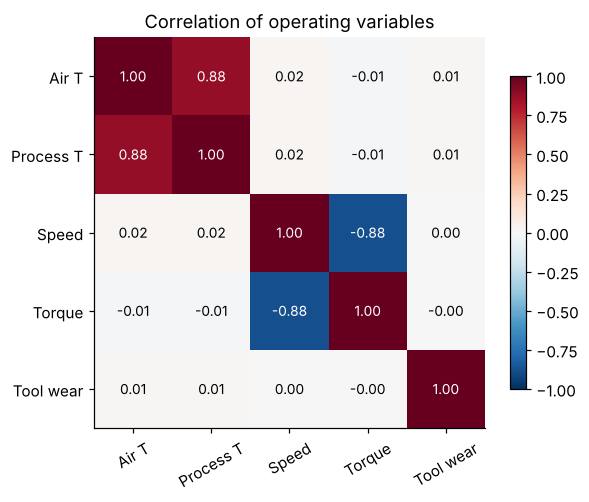

In [8]:
corr = df[num].corr()
fig, ax = plt.subplots(figsize=(5.6, 4.6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1); ax.grid(False)
short = ["Air T", "Process T", "Speed", "Torque", "Tool wear"]
ax.set_xticks(range(5), short, rotation=30); ax.set_yticks(range(5), short)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
fig.colorbar(im, shrink=0.8); ax.set_title("Correlation of operating variables")
fig.tight_layout(); fig.savefig(FIG / "eda_correlation.png", dpi=150)
corr.round(3)

## 5. Physically motivated derived quantities

Three quantities have a direct engineering meaning: the temperature difference between process and air (heat dissipation), mechanical power P = τ·ω (torque × angular speed), and the product tool wear × torque (cumulative strain on the tool). The dataset documentation describes the HDF, PWF and OSF failure modes in terms of thresholds on exactly these quantities, so we check how the labels relate to them.

In [9]:
d = df.copy()
d["temp_diff_K"] = d[S.PROCESS_TEMP] - d[S.AIR_TEMP]
d["power_W"] = d[S.TORQUE] * d[S.ROT_SPEED] * 2 * np.pi / 60
d["wear_torque_minNm"] = d[S.TOOL_WEAR] * d[S.TORQUE]

checks = {
    "HDF: temp diff < 8.6 K and speed < 1380 rpm": ((d.temp_diff_K < 8.6) & (d[S.ROT_SPEED] < 1380), d.HDF),
    "PWF: power < 3500 W or > 9000 W": ((d.power_W < 3500) | (d.power_W > 9000), d.PWF),
    "OSF: wear x torque > 11k/12k/13k minNm (L/M/H)": (d.wear_torque_minNm > d[S.TYPE].map({"L": 11000, "M": 12000, "H": 13000}).astype(float), d.OSF),
}
rows = []
for name, (rule, label) in checks.items():
    rows.append({"rule": name, "rule true": int(rule.sum()), "label = 1": int(label.sum()),
                 "agreement": f"{(rule.astype(int) == label).mean():.4%}"})
pd.DataFrame(rows)

,rule,rule true,label = 1,agreement
0,HDF: temp diff < 8.6 K and speed < 1380 rpm,115,115,100.0000%
1,PWF: power < 3500 W or > 9000 W,95,95,100.0000%
2,OSF: wear x torque > 11k/12k/13k minNm (L/M/H),98,98,100.0000%


Tool wear at TWF events: {'min': 198.0, '50%': 214.5, 'max': 253.0}


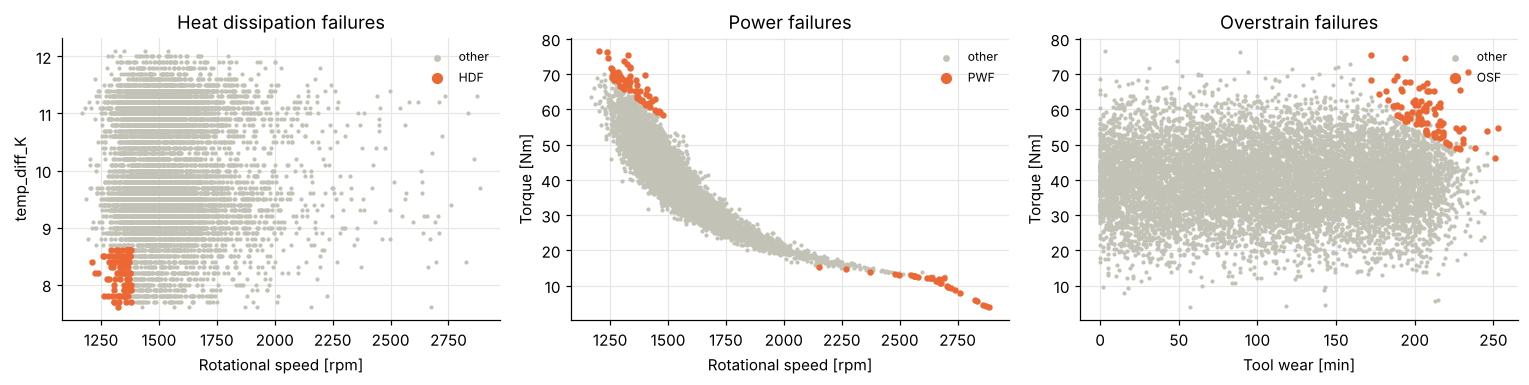

In [10]:
print("Tool wear at TWF events:", d.loc[d.TWF == 1, S.TOOL_WEAR].describe()[["min", "50%", "max"]].to_dict())
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for a, (x, y, lab, title) in zip(ax, [
        (S.ROT_SPEED, "temp_diff_K", "HDF", "Heat dissipation failures"),
        (S.ROT_SPEED, S.TORQUE, "PWF", "Power failures"),
        (S.TOOL_WEAR, S.TORQUE, "OSF", "Overstrain failures")]):
    a.scatter(d.loc[d[lab] == 0, x], d.loc[d[lab] == 0, y], s=3, color="#c3c2b7", label="other")
    a.scatter(d.loc[d[lab] == 1, x], d.loc[d[lab] == 1, y], s=10, color=ORANGE, label=lab)
    a.set_xlabel(x); a.set_ylabel(y); a.set_title(title); a.legend(frameon=False, fontsize=8, markerscale=2)
fig.tight_layout(); fig.savefig(FIG / "eda_failure_mode_regions.png", dpi=150)

**Observation.** HDF, PWF and OSF labels coincide with simple thresholds on the derived quantities, as the generator documentation describes. Models given these engineered features can recover most failures almost exactly, so results must be reported both **with and without** engineered features, and high scores must be interpreted as recovery of the simulator's rules rather than evidence about real machines.

## 6. Leakage check and split feasibility

In [11]:
assert_no_leakage(S.INPUT_FEATURES)  # passes: Type + 5 operating variables only
try:
    assert_no_leakage([*S.INPUT_FEATURES, "TWF"])
except Exception as e:
    print("Leakage guard works:", e)

from sklearn.model_selection import train_test_split
idx_trval, idx_test = train_test_split(df.index, test_size=0.15, stratify=df[S.MACHINE_FAILURE], random_state=42)
idx_train, idx_val = train_test_split(idx_trval, test_size=0.15 / 0.85, stratify=df.loc[idx_trval, S.MACHINE_FAILURE], random_state=42)
split = pd.DataFrame({name: [len(ix), int(df.loc[ix, S.MACHINE_FAILURE].sum())] for name, ix in
                      [("train", idx_train), ("validation", idx_val), ("test", idx_test)]}, index=["rows", "failures"]).T
split["failure rate"] = (split.failures / split.rows).round(4); split

Leakage guard works: Forbidden input columns for target 'Machine failure': ['TWF']


,rows,failures,failure rate
train,7000,237,0.0339
validation,1500,51,0.0340
test,1500,51,0.0340


In [12]:
per_mode = {m: {s: int(df.loc[ix, m].sum()) for s, ix in [("train", idx_train), ("validation", idx_val), ("test", idx_test)]}
            for m in modes}
pd.DataFrame(per_mode).T

,train,validation,test
TWF,33,8,5
HDF,82,12,21
PWF,69,15,11
OSF,66,17,15
RNF,15,3,1


**Observation.** A 70/15/15 stratified split leaves only about 51 failures in each of the validation and test sets, and only a handful of examples of rare modes (TWF, RNF) in held-out data. Metric estimates on the test set will therefore be noisy; model selection should use repeated stratified cross-validation on the training set, and test metrics should be reported with bootstrap confidence intervals.

In [13]:
eda = {
    "rows": int(len(df)), "failures": int(df[S.MACHINE_FAILURE].sum()),
    "failure_rate": float(df[S.MACHINE_FAILURE].mean()),
    "type_counts": df[S.TYPE].value_counts().to_dict(),
    "failure_rate_by_type": rate["failure rate"].round(4).to_dict(),
    "mode_counts": {m: int(df[m].sum()) for m in modes},
    "failures_without_mode": int(((df[S.MACHINE_FAILURE] == 1) & (n_modes == 0)).sum()),
    "modes_without_failure": int(((df[S.MACHINE_FAILURE] == 0) & (n_modes > 0)).sum()),
    "multi_mode_rows": int((n_modes > 1).sum()),
    "rule_agreement": {r["rule"]: r["agreement"] for r in rows},
    "split": split.to_dict("index"),
}
(ROOT / "reports" / "eda_summary.json").write_text(json.dumps(eda, indent=1, default=str))
print(json.dumps(eda, indent=1, default=str))

{
 "rows": 10000,
 "failures": 339,
 "failure_rate": 0.0339,
 "type_counts": {
  "L": 6000,
  "M": 2997,
  "H": 1003
 },
 "failure_rate_by_type": {
  "L": 0.0392,
  "M": 0.0277,
  "H": 0.0209
 },
 "mode_counts": {
  "TWF": 46,
  "HDF": 115,
  "PWF": 95,
  "OSF": 98,
  "RNF": 19
 },
 "failures_without_mode": 9,
 "modes_without_failure": 18,
 "multi_mode_rows": 24,
 "rule_agreement": {
  "HDF: temp diff < 8.6 K and speed < 1380 rpm": "100.0000%",
  "PWF: power < 3500 W or > 9000 W": "100.0000%",
  "OSF: wear x torque > 11k/12k/13k minNm (L/M/H)": "100.0000%"
 },
 "split": {
  "train": {
   "rows": 7000,
   "failures": 237,
   "failure rate": 0.0339
  },
  "validation": {
   "rows": 1500,
   "failures": 51,
   "failure rate": 0.034
  },
  "test": {
   "rows": 1500,
   "failures": 51,
   "failure rate": 0.034
  }
 }
}
